# Week 3: the agentic copilot

**Question.** What do tools, a critic and deterministic repair add on top of RAG, and why is test accuracy below dev?

**Design in one line.** The LLM plans and writes; **code** calculates dates, derives findings, picks the loan path and
checks the output. Every answer ends in a fixed JSON contract (behaviour, answer, citations, findings, deadlines,
drafts) that a UI and a scorer can both rely on.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


## 1. The deterministic tools, live (no model needed)

These run right now on the synthetic data. The LLM can call them but cannot override them.

In [2]:
from rto_copilot import tools as T
chk = T.check_case("DEMO-072")
print("Case", chk["case_id"], "|", chk["scenario"], "|", chk["case_status"])
print("Findings:", [f["code"] for f in chk["findings"]])
print("Escalation triggers:", chk["escalation_triggers"])
print("Form path:", chk["form_path"])

Case DEMO-072 | LOAN_ACTIVE_PENDING | REVIEW_REQUIRED
Findings: ['ENGINE_MISMATCH', 'FINANCIER_REVIEW_REQUIRED']
Escalation triggers: ['engine number on the declaration differs from the RC']
Form path: Loan running and the financier's written consent is not yet given: no transfer entry without it (MVA s.51(4)). Either obtain written consent or repay and file Form 35. Never marked ready; a draft request to the financier can be prepared.


In [3]:
d = T.compute_deadlines("2026-10-20", today="2026-11-10")
pd.DataFrame(d["deadlines"])[["rule_id", "party", "window_days", "due_date", "days_left", "status"]]

,rule_id,party,window_days,due_date,days_left,status
0,R-SELLER-REPORT-SAME-STATE,seller,14,2026-11-03,-7,overdue
1,R-BUYER-REPORT-ACT,buyer,30,2026-11-19,9,conflict
2,R-BUYER-APPLY-PARIVAHAN,buyer,14,2026-11-03,-7,conflict


In [4]:
print("Conflicts the copilot must surface:", d["conflicts"])
print("\nRelative date:", T.resolve_date("we sold it yesterday", "2026-11-10"))
try:
    T.resolve_date("last week", "2026-11-10")
except T.ToolError as e:
    print("Vague date is refused, not guessed:", e)

Conflicts the copilot must surface: [{'group': 'BUYER-WINDOW', 'rule_ids': ['R-BUYER-REPORT-ACT', 'R-BUYER-APPLY-PARIVAHAN'], 'due_dates': ['2026-11-19', '2026-11-03'], 'plan_to': '2026-11-03', 'note': 'The sources give different windows; show both dates and plan to the earlier one.'}]

Relative date: {'date': '2026-11-09', 'resolved_from': 'yesterday', 'today': '2026-11-10'}
Vague date is refused, not guessed: cannot resolve 'last week' to a single date; ask the user for the exact transfer date


**Business reading.** Dates and finding codes are *never* the model's opinion. `ENGINE_MISMATCH` fires when the declared
engine number differs from the RC, `FINANCIER_REVIEW_REQUIRED` fires when the loan is active and consent is pending.
That is why finding-code accuracy is 100% in every saved run.

## 2. The saved runs (Qwen3-8B)

In [5]:
runs = {"Dev, final (rule critic)": "w3_dev_final", "Test, final": "w3_test_final",
        "Dev, LLM critic (ablation)": "w3_dev_llm_critic", "Dev, 30% tool faults": "w3_dev_faults0.3"}
table = []
for label, folder in runs.items():
    s = json.load(open(config.RESULTS / "agent" / folder / "summary.json"))
    lo, hi = wilson_interval(round(s["end_to_end_accuracy"] * s["items"]), s["items"])
    table.append({"run": label, "n": s["items"], "end_to_end": s["end_to_end_accuracy"], "CI95": f"{lo:.2f} to {hi:.2f}",
                  "behaviour": s["behavior_accuracy"], "facts": s["must_include_coverage"], "citations": s["citation_ok_rate"],
                  "avg_latency_s": s["avg_wall_latency_s"], "avg_llm_calls": s["avg_llm_calls"]})
pd.DataFrame(table).set_index("run")

,n,end_to_end,CI95,behaviour,facts,citations,avg_latency_s,avg_llm_calls
run,,,,,,,,
"Dev, final (rule critic)",57,0.561,0.43 to 0.68,0.737,0.785,0.965,20.846,2.456
"Test, final",34,0.324,0.19 to 0.49,0.735,0.778,0.882,19.604,2.588
"Dev, LLM critic (ablation)",57,0.474,0.35 to 0.60,0.684,0.743,0.965,23.558,3.737
"Dev, 30% tool faults",57,0.474,0.35 to 0.60,0.702,0.734,0.877,8.990,2.509


* **LLM critic (ablation):** adding a second LLM as critic did *not* beat the rule critic (47% vs 56%) and costs
  more. The cheap deterministic critic is the better design here.
* **30% tool faults:** with a third of tool calls failing on purpose, accuracy falls to 47%, not to zero.
  The agent degrades gracefully; it does not crash or invent.

## 3. Why is test lower than dev? Look inside the six checks

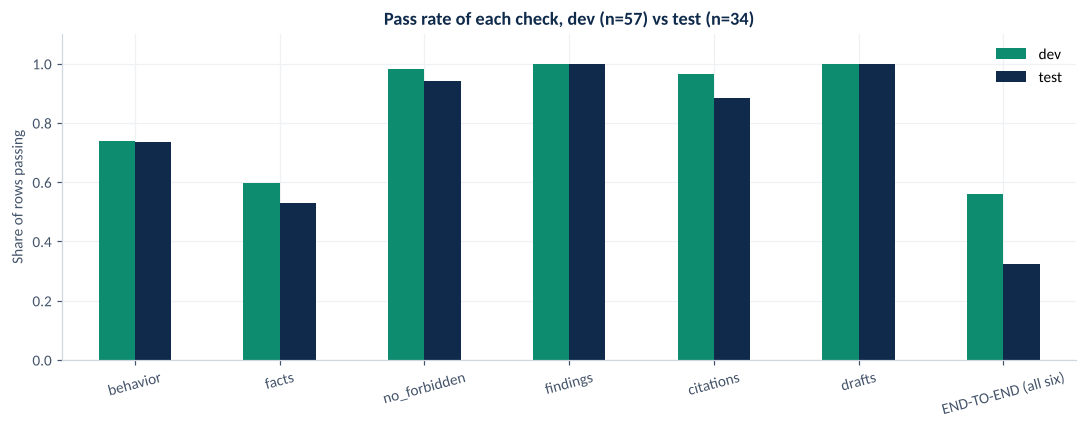

Near-miss rate (rows failing exactly one check): dev 0.158 | test 0.5


In [6]:
dev, test = nbkit.agent_run("w3_dev_final"), nbkit.agent_run("w3_test_final")
cr = {"dev": component_report(dev), "test": component_report(test)}
comp = pd.DataFrame({k: v["components"] for k, v in cr.items()})
comp.loc["END-TO-END (all six)"] = [cr["dev"]["end_to_end"], cr["test"]["end_to_end"]]
fig, ax = plt.subplots(figsize=(10, 4))
comp.plot.bar(ax=ax, color=[nbkit.TEAL, nbkit.NAVY], rot=15); ax.set_ylim(0, 1.1)
ax.set_title("Pass rate of each check, dev (n=57) vs test (n=34)"); ax.set_ylabel("Share of rows passing")
plt.tight_layout(); plt.show()
print("Near-miss rate (rows failing exactly one check): dev", cr["dev"]["near_miss_rate"], "| test", cr["test"]["near_miss_rate"])

**This is the key finding.**

* **Behaviour accuracy is identical** (73.7% dev, 73.5% test). The copilot picks the right kind of response equally
  well on unseen rows.
* **Finding codes and drafts are perfect** on both.
* The gap lives in **facts** (a required phrase missing: 60% vs 53%) and **citations** (97% vs 88%), and the strict
  AND of six checks amplifies small differences. Half the failing test rows missed by exactly one check.

So "test is worse" is mostly "a handful of rows missed one required phrase", on a 34-row split where one row is
three points. That is a measurement and wording issue much more than a reasoning collapse.

## 4. Which categories are weak? (with honest error bars)

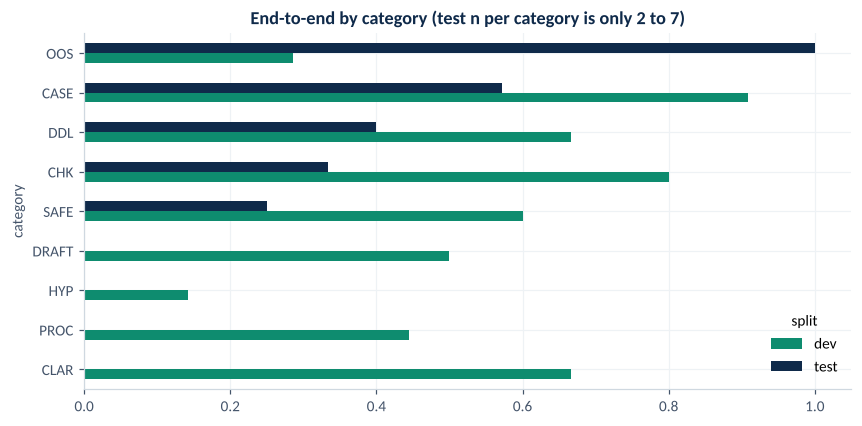

n        k     
split    dev test dev test
category                  
CASE      11    7  10    4
CHK        5    3   4    1
CLAR       3    2   2    0
DDL        6    5   4    2
DRAFT      4    2   2    0
HYP        7    4   1    0
OOS        7    3   2    3
PROC       9    4   4    0
SAFE       5    4   3    1

In [7]:
df = pd.DataFrame([{**r, "split": "dev"} for r in dev] + [{**r, "split": "test"} for r in test])
cat = df.groupby(["category", "split"]).agg(n=("end_to_end", "size"), k=("end_to_end", "sum"), behaviour=("behavior_ok", "mean"), facts=("include_all", "mean")).reset_index()
cat["e2e"] = cat.k / cat.n
pv = cat.pivot(index="category", columns="split", values="e2e").sort_values("test")
fig, ax = plt.subplots(figsize=(9, 4.2))
pv.plot.barh(ax=ax, color=[nbkit.TEAL, nbkit.NAVY]); ax.set_xlim(0, 1.05); ax.set_title("End-to-end by category (test n per category is only 2 to 7)")
plt.show()
cat.pivot(index="category", columns="split", values=["n", "k"]).fillna(0).astype(int)

**Reading with care.** PROC and HYP score 0 on test, but there are only 4 rows each, so the plausible range is 0% to 49%.
These are the categories to over-sample in v2, which is exactly what the 98 new rows do (PROC +12, HYP +10).

## 5. What kind of failure is it?

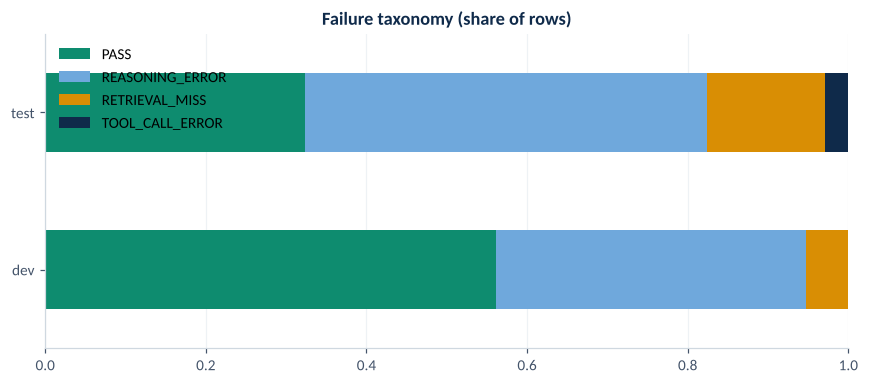

,dev,test
PASS,0.561,0.324
REASONING_ERROR,0.386,0.500
RETRIEVAL_MISS,0.053,0.147
TOOL_CALL_ERROR,0.000,0.029


In [8]:
tax = pd.DataFrame({"dev": pd.Series(json.load(open(config.RESULTS / "agent/w3_dev_final/summary.json"))["failure_taxonomy"]),
                    "test": pd.Series(json.load(open(config.RESULTS / "agent/w3_test_final/summary.json"))["failure_taxonomy"])}).fillna(0)
tax = tax.div(tax.sum()).round(3)
fig, ax = plt.subplots(figsize=(8, 3.6)); tax.T.plot.barh(stacked=True, ax=ax, color=[nbkit.TEAL, nbkit.SKY, nbkit.AMBER, nbkit.NAVY])
ax.set_title("Failure taxonomy (share of rows)"); ax.set_xlim(0, 1); plt.tight_layout(); plt.show()
tax

No hallucination rows in either split, and the dominant non-pass type is *reasoning or wording* (the answer is
safe but misses a required phrase). Retrieval misses are 5% on dev but 15% on test (5 of 34 rows), which is the other thing to watch. For a compliance-adjacent use case, "safe but
incomplete" is the failure mode you want.

## 6. One trace, end to end

In [9]:
traces = nbkit.load_jsonl(config.RESULTS / "agent/w3_dev_final/traces.jsonl")
first = traces[0]["trace_id"]
spans = pd.DataFrame([{"span": s["name"], "ms": s["duration_ms"]} for s in traces if s["trace_id"] == first])
spans.sort_values("ms", ascending=False)

,span,ms
7,agent.turn,18315.5
3,executor.tools,9838.3
2,tool.search_corpus,9835.7
5,executor.compose,5738.2
4,llm.executor,5736.2
1,planner,2732.9
0,llm.planner,2729.3
6,critic,0.0


## 7. Compare any new run automatically

After a live run on v2, this cell finds runs that are not part of the saved set and reports them with intervals.

In [10]:
known = set(runs.values())
new_runs = [p.name for p in sorted((config.RESULTS / "agent").iterdir()) if p.is_dir() and p.name not in known and (p / "answers.jsonl").exists()]
if not new_runs:
    print("No new runs yet. Run (needs the endpoint):\n  RTO_EVAL_SET=v2 python -m rto_copilot.agent_eval --split dev --cohort v2")
for name in new_runs:
    r = nbkit.agent_run(name); cr2 = component_report(r)
    print(name, "n =", cr2["n"], "e2e =", cr2["end_to_end"], "CI95 =", cr2["ci95"], "components =", cr2["components"])

No new runs yet. Run (needs the endpoint):
  RTO_EVAL_SET=v2 python -m rto_copilot.agent_eval --split dev --cohort v2


## 8. Live: ask the agent a question (optional)

In [11]:
if RUN_LIVE:
    from rto_copilot.serving import Copilot
    cp = Copilot.from_env()
    out = cp.ask("notebook", "Which forms do we need if there is no loan?", "2026-11-20")
    print(out["final"]["behavior"], "|", out["final"]["answer"][:600])
else:
    print("Skipped (RUN_LIVE is False). Case checks above ran without a model.")

Skipped (RUN_LIVE is False). Case checks above ran without a model.
